In [47]:
import pickle
import sys
import os
import torch
import argparse
import copy 
import mujoco 
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from train_sam_ppo import main as train_func
import gymnasium as gym 
from sam_ppo_continuous import PPO_continuous

/Users/carlofiammenghi/Desktop/2nd_semester/ATML/2326_Flat_Reward_in_Policy_Par.pdf

In [48]:
def evaluate_policy(agent, env_name, noise_std, state_norm, episodes=10):
    env = gym.make(env_name)
    total_reward = 0
    
    for _ in range(episodes):
        state, _ = env.reset()
        state = state_norm(state, update=False)
        done = False
        while not done:
            # Usa agent.evaluate() che gestisce internamente torch.no_grad()
            action = agent.evaluate(state)
            
            # AGGIUNGI IL RUMORE (Il cuore del test di robustezza)
            if noise_std > 0:
                noise = np.random.normal(0, noise_std, size=action.shape)
                action = action + noise
            
            # Clip dell azione per non uscire dai limiti dell ambiente
            action = np.clip(action, env.action_space.low, env.action_space.high)
            
            state, reward, terminated, truncated, _ = env.step(action)
            state = state_norm(state, update=False)
            done = terminated or truncated
            total_reward += reward
            
    return total_reward / episodes

In [49]:
# 1. Prepariamo le dimensioni (devono corrispondere al tuo Hopper-v4)
env_temp = gym.make("Hopper-v4")
state_dim = env_temp.observation_space.shape[0]
action_dim = env_temp.action_space.shape[0]
max_action = float(env_temp.action_space.high[0])

# 2. Definiamo gli agenti (usando i parametri dello YAML)
def load_agent(path, use_sam=False):
    # Carica la configurazione di base dal file YAML
    with open("configs/Hopper.yaml", 'r') as file:
        config = yaml.safe_load(file)
    
    # Crea un oggetto args contenente i parametri dello YAML
    args = argparse.Namespace(**config)
    
    # Aggiungi le dimensioni specifiche lette dall'environment
    args.state_dim = state_dim
    args.action_dim = action_dim
    args.max_action = max_action
    
    # Impostazioni specifiche per SAM PPO
    args.use_sam = use_sam
    args.rho = 0.01 if use_sam else 0.0
    
    # Impostazioni di default aggiuntive richieste dalla classe che potrebbero mancare nello YAML
    args.set_adam_eps = False
    args.use_adv_norm = False
    args.adaptive_alpha = False
    args.use_grad_clip = config.get("use_grad_clip", True)
    args.use_lr_decay = config.get("use_lr_decay", True)
    args.use_orthogonal_init = config.get("use_orthogonal_init", True)
    args.use_tanh = config.get("use_tanh", True)
    # Istanziamo l'agente passando il singolo oggetto args
    agent = PPO_continuous(args)
    
    # Carichiamo i pesi salvati
    agent.actor.load_state_dict(torch.load(path))
    agent.actor.eval() # Impostiamo in modalità valutazione
    
    return agent

# 1. Definiamo una funzione di caricamento universale
def get_agent(env_name, model_path, config_path, use_sam=False):
    # Ricava le dimensioni direttamente dall'ambiente corretto
    env_temp = gym.make(env_name)
    
    with open(config_path, 'r') as file:
        config = yaml.safe_load(file)
        
    args = argparse.Namespace(**config)
    args.state_dim = env_temp.observation_space.shape[0]
    args.action_dim = env_temp.action_space.shape[0]
    args.max_action = float(env_temp.action_space.high[0])
    
    args.use_sam = use_sam
    args.rho = config.get('rho', 0.01) if use_sam else 0.0
    
    args.set_adam_eps = False
    args.use_adv_norm = False
    args.adaptive_alpha = False
    args.use_grad_clip = config.get("use_grad_clip", True)
    args.use_lr_decay = config.get("use_lr_decay", True)
    args.use_orthogonal_init = config.get("use_orthogonal_init", True)
    args.use_tanh = config.get("use_tanh", True)

    agent = PPO_continuous(args)
    agent.actor.load(model_path)
    agent.actor.eval()
    norm_path = model_path.replace("_actor", "_state_norm")
    with open(norm_path, "rb") as f:
        state_norm = pickle.load(f)
    return agent, state_norm



# 2. Carichiamo tutti i 4 agenti
print("Caricamento modelli in corso...")
hopper_sam, hopper_sam_norm = get_agent("Hopper-v4", "./models/SAM_PPO_Hopper-v4_rho_0.01_default_actor", "configs/Hopper.yaml", use_sam=True)
hopper_ppo, hopper_ppo_norm = get_agent("Hopper-v4", "./models/PPO_Hopper-v4_default_actor", "configs/Hopper.yaml", use_sam=False)

walker_sam, walker_sam_norm = get_agent("Walker2d-v4", "./models/SAM_PPO_Walker2d-v4_rho_0.008_default_actor", "configs/walker.yaml", use_sam=True)
walker_ppo, walker_ppo_norm = get_agent("Walker2d-v4", "./models/PPO_Walker2d-v4_default_actor", "configs/walker.yaml", use_sam=False)

cheetah_sam, cheetah_sam_norm = get_agent("HalfCheetah-v4", "./models/SAM_PPO_HalfCheetah-v4_rho_0.01_default_actor", "configs/halfcheetah.yaml", use_sam=True)
cheetah_ppo, cheetah_ppo_norm = get_agent("HalfCheetah-v4", "./models/PPO_HalfCheetah-v4_default_actor", "configs/halfcheetah.yaml", use_sam=False)
print("Modelli caricati con successo!\n")


# 3. Carichiamo i file (Modifica i nomi dei file se diversi!)
try:
    # Removed the .pth extension, added _actor
    sam_agent = load_agent("./models/SAM_PPO_Hopper-v4_rho_0.01_default_actor", use_sam=True)
    
    # If you haven't trained standard PPO, you can comment this out or train it first
    # ppo_agent = load_agent("./models/PPO_Hopper-v4_default_actor", use_sam=False)
    
    print("Agenti caricati con successo! ")
except Exception as e:
    print(f"Errore: {e}")

# Eseguiamo le valutazioni
noise_range = np.linspace(0, 0.5, 6)
hopper_sam_rewards, hopper_ppo_rewards = [], []
walker_sam_rewards, walker_ppo_rewards = [], []

print("Valutazione Hopper-v4...")
for noise in noise_range:
    hopper_sam_rewards.append(evaluate_policy(hopper_sam, "Hopper-v4", noise, hopper_sam_norm))
    hopper_ppo_rewards.append(evaluate_policy(hopper_ppo, "Hopper-v4", noise, hopper_ppo_norm))

print("Valutazione Walker2d-v4...")
for noise in noise_range:
    walker_sam_rewards.append(evaluate_policy(walker_sam, "Walker2d-v4", noise, walker_sam_norm))
    walker_ppo_rewards.append(evaluate_policy(walker_ppo, "Walker2d-v4", noise, walker_ppo_norm))

cheetah_sam_rewards, cheetah_ppo_rewards = [], []
print("Valutazione HalfCheetah-v4...")
for noise in noise_range:
    cheetah_sam_rewards.append(evaluate_policy(cheetah_sam, "HalfCheetah-v4", noise, cheetah_sam_norm))
    cheetah_ppo_rewards.append(evaluate_policy(cheetah_ppo, "HalfCheetah-v4", noise, cheetah_ppo_norm))


/opt/anaconda3/envs/rrl_env/lib/python3.9/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment Hopper-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
/opt/anaconda3/envs/rrl_env/lib/python3.9/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment Walker2d-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
/opt/anaconda3/envs/rrl_env/lib/python3.9/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment HalfCheetah-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(


Caricamento modelli in corso...
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.01
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: False, rho: 0.0
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.008
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: False, rho: 0.0
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.008
------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: False, rho: 0.0
Modelli caricati con successo!

------use_orthogonal_init------
------use_orthogonal_init------
Use SAM: True, rho: 0.01
Agenti caricati con successo! 
Valutazione Hopper-v4...
Valutazione Walker2d-v4...
Valutazione HalfCheetah-v4...


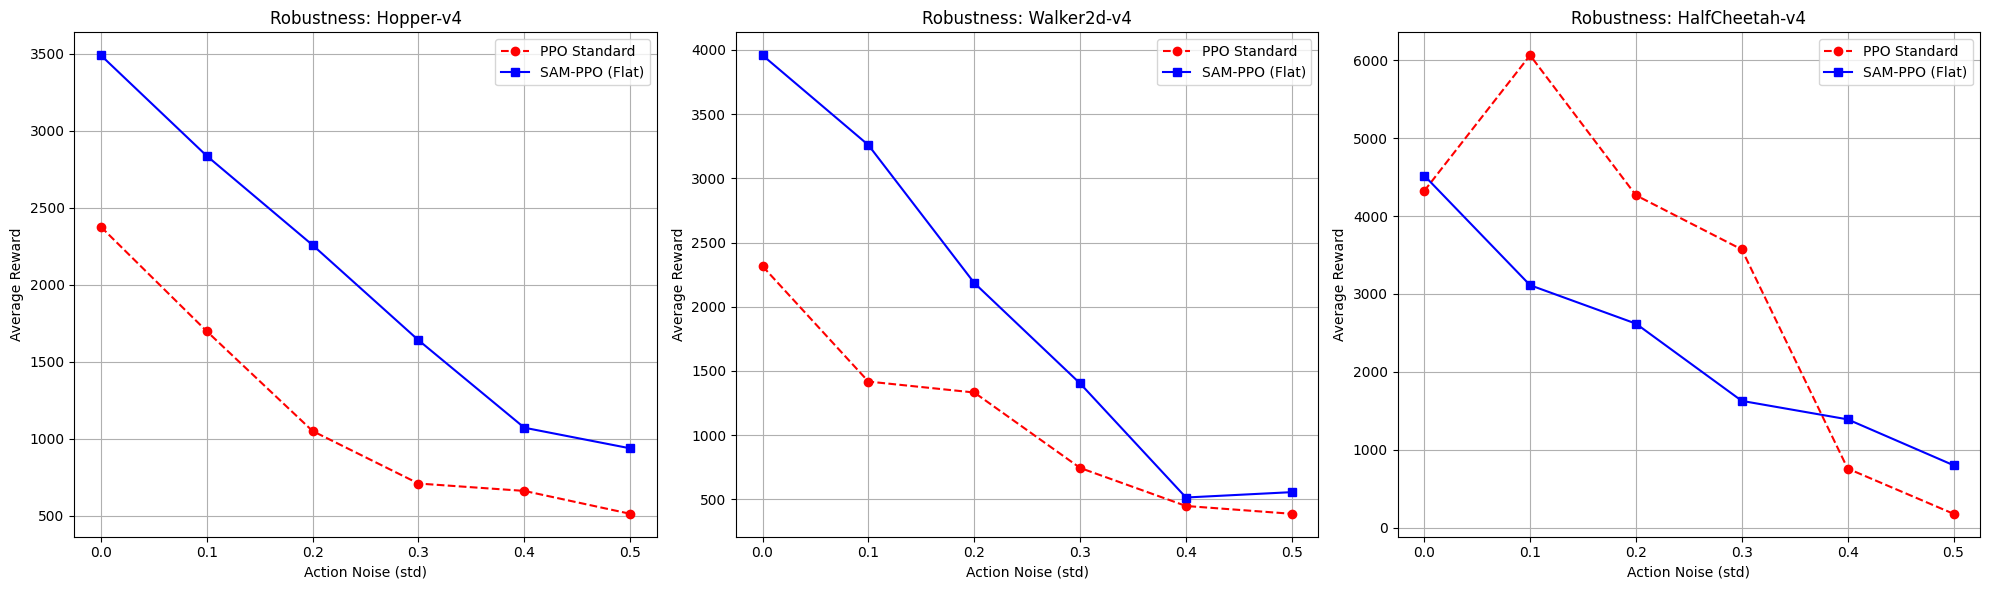

In [50]:
# 4. Creiamo il grafico
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].plot(noise_range, hopper_ppo_rewards, label="PPO Standard", marker="o", color="red", linestyle="--")
axes[0].plot(noise_range, hopper_sam_rewards, label="SAM-PPO (Flat)", marker="s", color="blue", linestyle="-")
axes[0].set_title("Robustness: Hopper-v4")
axes[0].set_xlabel("Action Noise (std)")
axes[0].set_ylabel("Average Reward")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(noise_range, walker_ppo_rewards, label="PPO Standard", marker="o", color="red", linestyle="--")
axes[1].plot(noise_range, walker_sam_rewards, label="SAM-PPO (Flat)", marker="s", color="blue", linestyle="-")
axes[1].set_title("Robustness: Walker2d-v4")
axes[1].set_xlabel("Action Noise (std)")
axes[1].set_ylabel("Average Reward")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(noise_range, cheetah_ppo_rewards, label="PPO Standard", marker="o", color="red", linestyle="--")
axes[2].plot(noise_range, cheetah_sam_rewards, label="SAM-PPO (Flat)", marker="s", color="blue", linestyle="-")
axes[2].set_title("Robustness: HalfCheetah-v4")
axes[2].set_xlabel("Action Noise (std)")
axes[2].set_ylabel("Average Reward")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig("comparison_results.png", dpi=300)
plt.show()


In [51]:
def set_friction(env, geom_ids, friction_factors):
    model = env.unwrapped.model
    for geom_id in geom_ids:
        model.geom_friction[geom_id] = friction_factors

def set_mass(env, body_id, mass_factor, original_masses):
    model = env.unwrapped.model
    model.body_mass[body_id] = original_masses[body_id] * mass_factor

def evaluate_mass_friction(agent, env_name, state_norm, test_type='mass'):
    env = gym.make(env_name)
    s, _ = env.reset(seed=42)
    
    if env_name == 'HalfCheetah-v4':
        fric_bodies = ['ffoot']
        mass_bodies = ['torso']
    elif env_name == 'Walker2d-v4':
        fric_bodies = ['foot_left']
        mass_bodies = ['torso']
    elif env_name == 'Hopper-v4':
        fric_bodies = ['foot']
        mass_bodies = ['torso']
        
    original_masses = {}
    for body in mass_bodies:
        b_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, body)
        original_masses[b_id] = env.unwrapped.model.body_mass[b_id]
        
    original_frictions = {}
    for body in fric_bodies:
        b_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, body)
        geom_ids = [i for i, geom_body in enumerate(env.unwrapped.model.geom_bodyid) if geom_body == b_id]
        original_frictions[body] = {geom_id: env.unwrapped.model.geom_friction[geom_id].copy() for geom_id in geom_ids}

    factors = np.linspace(0.5, 1.5, 11)
    results = []
    
    for f in factors:
        rewards = []
        for _ in range(5):
            env.reset(seed=np.random.randint(1000))
            
            if test_type == 'mass':
                for body in mass_bodies:
                    b_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, body)
                    set_mass(env, b_id, f, original_masses)
            elif test_type == 'friction':
                for body in fric_bodies:
                    b_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, body)
                    g_ids = [i for i, geom_body in enumerate(env.unwrapped.model.geom_bodyid) if geom_body == b_id]
                    for g_id in g_ids:
                        scaled_frictions = original_frictions[body][g_id].copy()
                        scaled_frictions[:2] *= f
                        set_friction(env, [g_id], scaled_frictions)
            
            s, _ = env.reset()
            if state_norm is not None:
                s = state_norm(s, update=False)
            
            done = False
            truncated = False
            episode_reward = 0
            while not (done or truncated):
                a = agent.evaluate(s)
                s_, r, done, truncated, _ = env.step(a)
                if state_norm is not None:
                    s_ = state_norm(s_, update=False)
                episode_reward += r
                s = s_
            rewards.append(episode_reward)
        results.append(np.mean(rewards))
        
    return factors, results

print("Funzioni per il calcolo della massa e dell'attrito caricate!")


Funzioni per il calcolo della massa e dell'attrito caricate!


In [52]:
mass_results = {}
envs = ["Hopper-v4", "Walker2d-v4", "HalfCheetah-v4"]
agents = [
    ("Hopper", hopper_ppo, hopper_sam, hopper_ppo_norm, hopper_sam_norm),
    ("Walker2d", walker_ppo, walker_sam, walker_ppo_norm, walker_sam_norm),
    ("HalfCheetah", cheetah_ppo, cheetah_sam, cheetah_ppo_norm, cheetah_sam_norm)
]

print("Valutazione Robustezza MASSA in corso (circa 1 minuto)...")
for name, ppo, sam, ppo_norm, sam_norm in agents:
    print(f"Valutando {name}...")
    factors, ppo_res = evaluate_mass_friction(ppo, f"{name}-v4", ppo_norm, test_type='mass')
    _, sam_res = evaluate_mass_friction(sam, f"{name}-v4", sam_norm, test_type='mass')
    mass_results[name] = {"factors": factors, "ppo": ppo_res, "sam": sam_res}

print("Valutazione MASSA completata!")


Valutazione Robustezza MASSA in corso (circa 1 minuto)...
Valutando Hopper...
Valutando Walker2d...
Valutando HalfCheetah...
Valutazione MASSA completata!


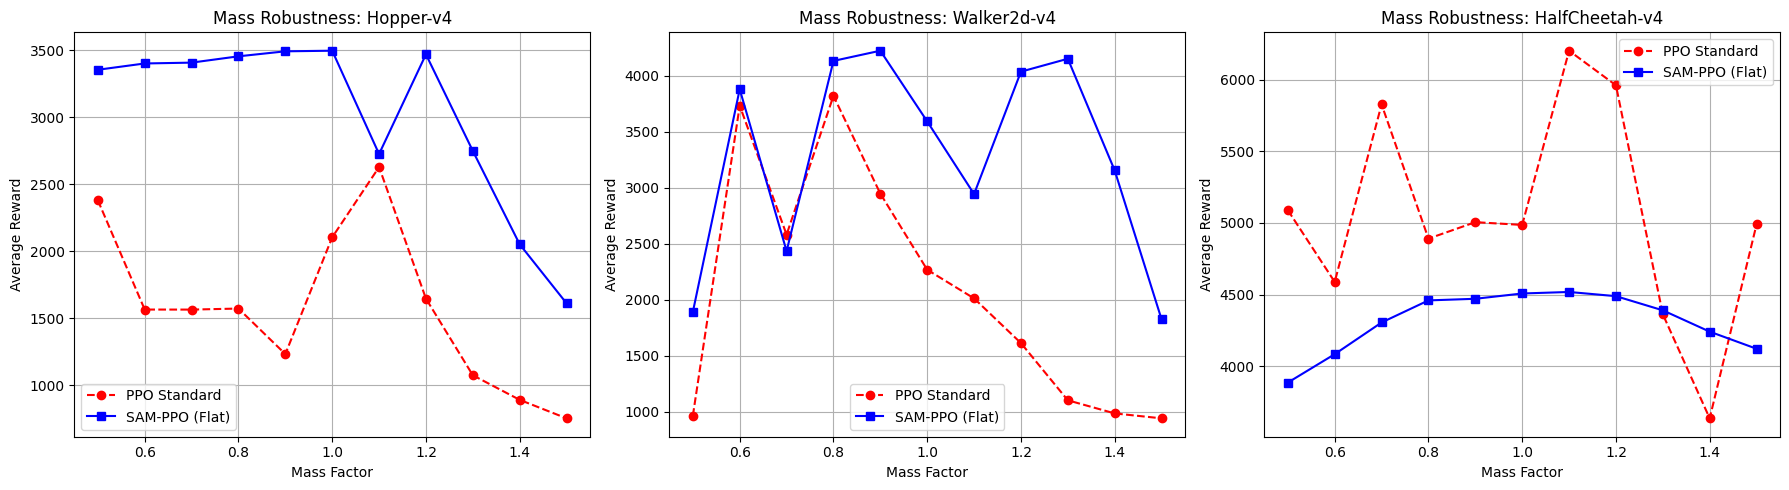

In [53]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for idx, name in enumerate(["Hopper", "Walker2d", "HalfCheetah"]):
    axs[idx].plot(mass_results[name]["factors"], mass_results[name]["ppo"], 'ro--', label='PPO Standard')
    axs[idx].plot(mass_results[name]["factors"], mass_results[name]["sam"], 'bs-', label='SAM-PPO (Flat)')
    axs[idx].set_title(f'Mass Robustness: {name}-v4')
    axs[idx].set_xlabel('Mass Factor')
    axs[idx].set_ylabel('Average Reward')
    axs[idx].grid(True)
    axs[idx].legend()

plt.tight_layout()
plt.savefig('images plotted/mass_robustness.png', dpi=300)
plt.show()


In [54]:
fric_results = {}

print("Valutazione Robustezza ATTRITO in corso (circa 1 minuto)...")
for name, ppo, sam, ppo_norm, sam_norm in agents:
    print(f"Valutando {name}...")
    factors, ppo_res = evaluate_mass_friction(ppo, f"{name}-v4", ppo_norm, test_type='friction')
    _, sam_res = evaluate_mass_friction(sam, f"{name}-v4", sam_norm, test_type='friction')
    fric_results[name] = {"factors": factors, "ppo": ppo_res, "sam": sam_res}

print("Valutazione ATTRITO completata!")


Valutazione Robustezza ATTRITO in corso (circa 1 minuto)...
Valutando Hopper...
Valutando Walker2d...
Valutando HalfCheetah...
Valutazione ATTRITO completata!


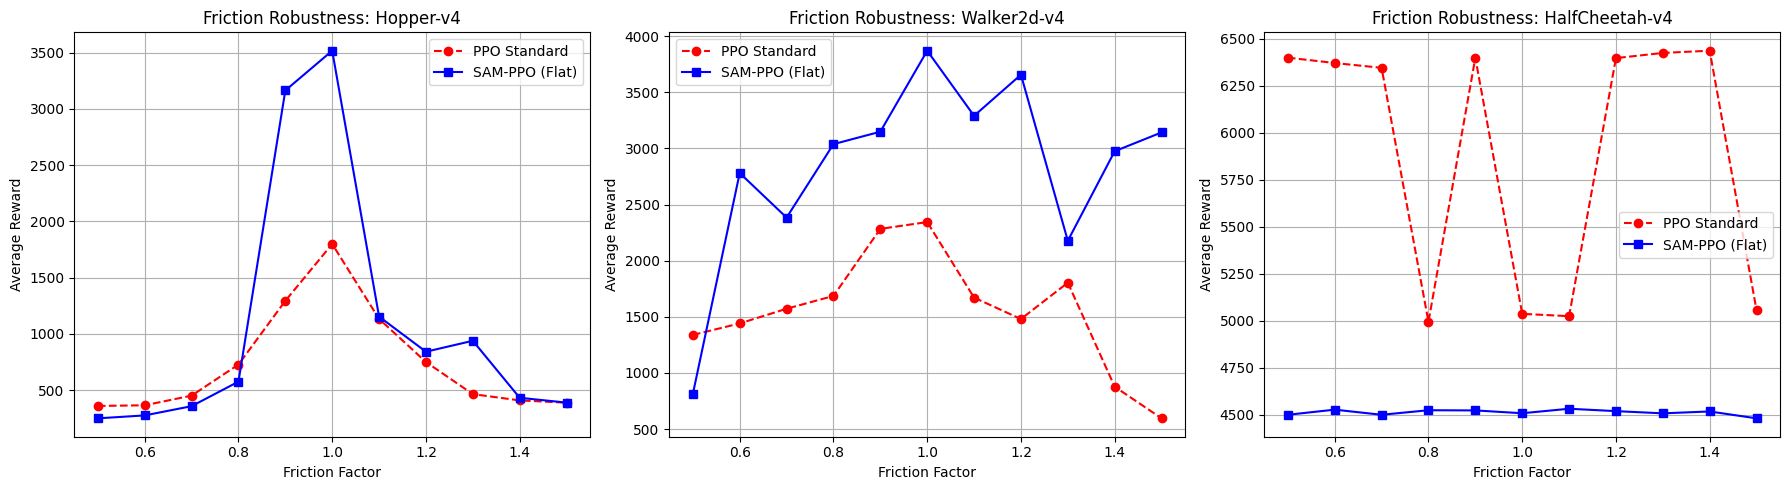

In [55]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for idx, name in enumerate(["Hopper", "Walker2d", "HalfCheetah"]):
    axs[idx].plot(fric_results[name]["factors"], fric_results[name]["ppo"], 'ro--', label='PPO Standard')
    axs[idx].plot(fric_results[name]["factors"], fric_results[name]["sam"], 'bs-', label='SAM-PPO (Flat)')
    axs[idx].set_title(f'Friction Robustness: {name}-v4')
    axs[idx].set_xlabel('Friction Factor')
    axs[idx].set_ylabel('Average Reward')
    axs[idx].grid(True)
    axs[idx].legend()

plt.tight_layout()
plt.savefig('images plotted/friction_robustness.png', dpi=300)
plt.show()


Valutazione Robustezza SENSORI (State Noise) in corso (circa 1 minuto)...
Valutando Hopper...
Valutando Walker2d...
Valutando HalfCheetah...


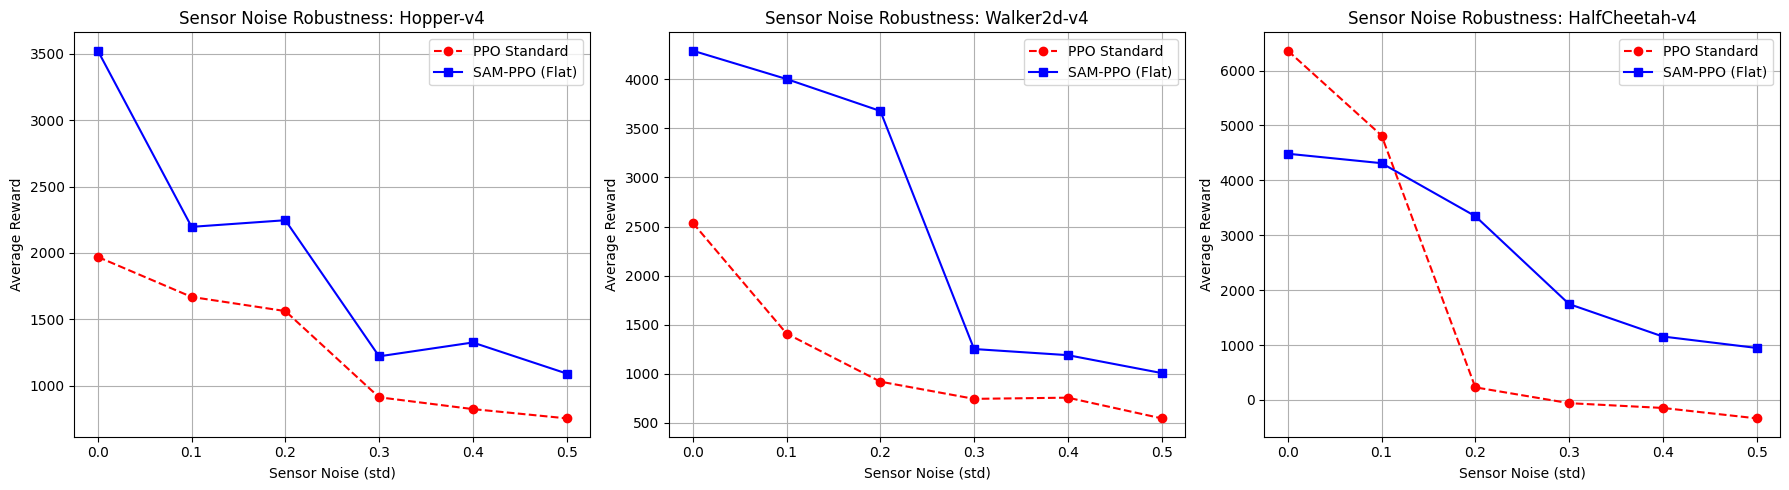

Valutazione SENSORI completata!


In [56]:
# --- TEST ROBUSTEZZA SENSORI (STATE/OBSERVATION NOISE) ---
# Aggiungiamo rumore ai sensori (Observation) del robot
def evaluate_state_noise(agent, env_name, state_norm, noise_stds):
    env = gym.make(env_name)
    results = []
    
    for std in noise_stds:
        rewards = []
        for _ in range(5):
            s, _ = env.reset(seed=np.random.randint(1000))
            if state_norm is not None:
                s = state_norm(s, update=False)
            
            done = False
            truncated = False
            episode_reward = 0
            while not (done or truncated):
                # Aggiungiamo rumore gaussiano allo STATO (Sensori difettosi) prima di decidere l'azione
                noisy_s = s + np.random.normal(0, std, size=s.shape)
                a = agent.evaluate(noisy_s)
                
                s_, r, done, truncated, _ = env.step(a)
                if state_norm is not None:
                    s_ = state_norm(s_, update=False)
                episode_reward += r
                s = s_
            rewards.append(episode_reward)
        results.append(np.mean(rewards))
        
    return results

noise_stds = np.linspace(0.0, 0.5, 6)
noise_results = {}

print("Valutazione Robustezza SENSORI (State Noise) in corso (circa 1 minuto)...")
for name, ppo, sam, ppo_norm, sam_norm in agents:
    print(f"Valutando {name}...")
    ppo_res = evaluate_state_noise(ppo, f"{name}-v4", ppo_norm, noise_stds)
    sam_res = evaluate_state_noise(sam, f"{name}-v4", sam_norm, noise_stds)
    noise_results[name] = {"ppo": ppo_res, "sam": sam_res}

# Plot State Noise
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for idx, name in enumerate(["Hopper", "Walker2d", "HalfCheetah"]):
    axs[idx].plot(noise_stds, noise_results[name]["ppo"], 'ro--', label='PPO Standard')
    axs[idx].plot(noise_stds, noise_results[name]["sam"], 'bs-', label='SAM-PPO (Flat)')
    axs[idx].set_title(f'Sensor Noise Robustness: {name}-v4')
    axs[idx].set_xlabel('Sensor Noise (std)')
    axs[idx].set_ylabel('Average Reward')
    axs[idx].grid(True)
    axs[idx].legend()

plt.tight_layout()
import os
os.makedirs('images plotted', exist_ok=True)
plt.savefig('images plotted/sensor_noise_robustness.png', dpi=300)
plt.show()
print("Valutazione SENSORI completata!")


Generazione Heatmap 2D su HalfCheetah in corso (ci vorranno circa 2-3 minuti)...


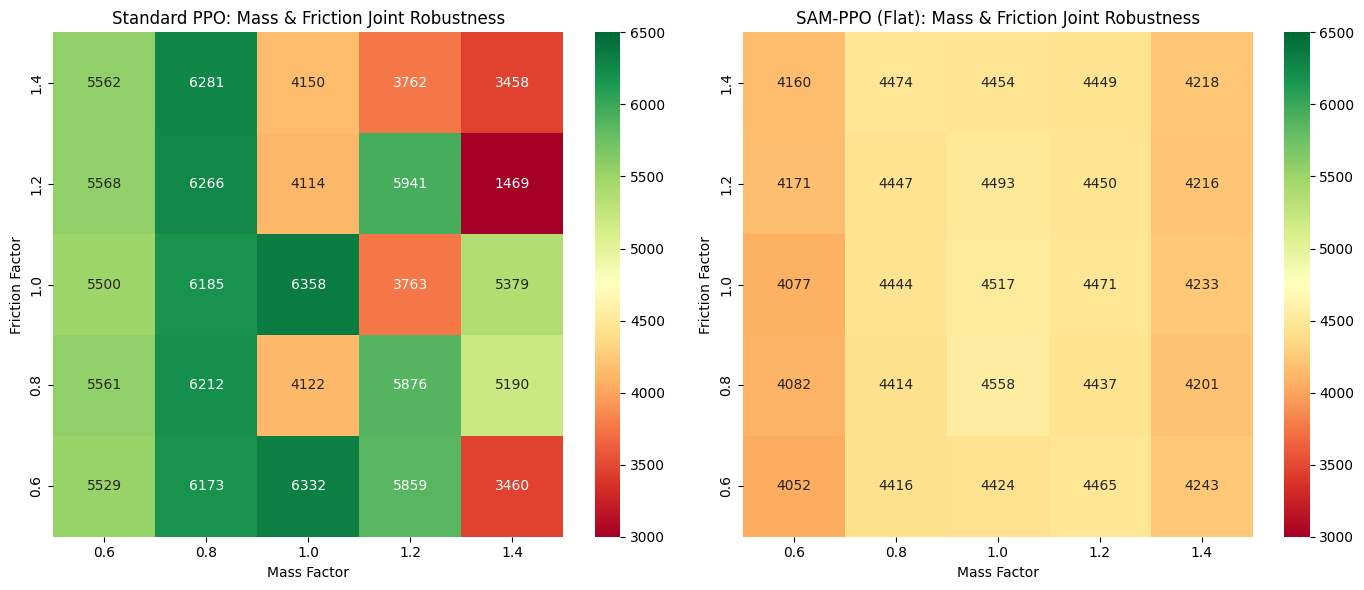

Heatmap generata con successo!


In [57]:
# --- TEST HEATMAP 2D (MASSA + ATTRITO CONGIUNTI) SU HALFCHEETAH ---
def evaluate_heatmap_halfcheetah(agent, state_norm):
    env = gym.make("HalfCheetah-v4")
    fric_bodies = ['ffoot']
    mass_bodies = ['torso']
    
    env.reset(seed=42)
    b_mass_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, mass_bodies[0])
    original_mass = env.unwrapped.model.body_mass[b_mass_id]
    
    b_fric_id = mujoco.mj_name2id(env.unwrapped.model, mujoco.mjtObj.mjOBJ_BODY, fric_bodies[0])
    geom_ids = [i for i, geom_body in enumerate(env.unwrapped.model.geom_bodyid) if geom_body == b_fric_id]
    original_frictions = {geom_id: env.unwrapped.model.geom_friction[geom_id].copy() for geom_id in geom_ids}

    # Griglia 5x5 per Massa e Attrito
    mass_factors = np.linspace(0.6, 1.4, 5) 
    fric_factors = np.linspace(0.6, 1.4, 5)
    
    heatmap_data = np.zeros((len(fric_factors), len(mass_factors)))
    
    for i, f_fric in enumerate(fric_factors):
        for j, f_mass in enumerate(mass_factors):
            rewards = []
            for _ in range(3): # 3 episodi per combinazione per essere veloci
                env.reset(seed=np.random.randint(1000))
                
                # Applica Massa
                set_mass(env, b_mass_id, f_mass, {b_mass_id: original_mass})
                
                # Applica Attrito
                for g_id in geom_ids:
                    scaled_frictions = original_frictions[g_id].copy()
                    scaled_frictions[:2] *= f_fric
                    set_friction(env, [g_id], scaled_frictions)
                
                s, _ = env.reset()
                if state_norm is not None:
                    s = state_norm(s, update=False)
                
                done = False
                truncated = False
                episode_reward = 0
                while not (done or truncated):
                    a = agent.evaluate(s)
                    s_, r, done, truncated, _ = env.step(a)
                    if state_norm is not None:
                        s_ = state_norm(s_, update=False)
                    episode_reward += r
                    s = s_
                rewards.append(episode_reward)
            heatmap_data[i, j] = np.mean(rewards)
            
    return mass_factors, fric_factors, heatmap_data

print("Generazione Heatmap 2D su HalfCheetah in corso (ci vorranno circa 2-3 minuti)...")

# Estraiamo gli agenti di HalfCheetah dalla lista agents
cheetah_ppo_agent = [a[1] for a in agents if a[0]=="HalfCheetah"][0]
cheetah_sam_agent = [a[2] for a in agents if a[0]=="HalfCheetah"][0]
cheetah_ppo_norm_agent = [a[3] for a in agents if a[0]=="HalfCheetah"][0]
cheetah_sam_norm_agent = [a[4] for a in agents if a[0]=="HalfCheetah"][0]

m_factors, f_factors, heat_ppo = evaluate_heatmap_halfcheetah(cheetah_ppo_agent, cheetah_ppo_norm_agent)
_, _, heat_sam = evaluate_heatmap_halfcheetah(cheetah_sam_agent, cheetah_sam_norm_agent)

# Plot Heatmap
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Usiamo la colormap verde-rosso per evidenziare i punteggi alti
vmin_val = 3000
vmax_val = 6500

sns.heatmap(heat_ppo, xticklabels=np.round(m_factors, 1), yticklabels=np.round(f_factors, 1), 
            ax=axs[0], cmap="RdYlGn", vmin=vmin_val, vmax=vmax_val, annot=True, fmt=".0f")
axs[0].set_title("Standard PPO: Mass & Friction Joint Robustness")
axs[0].set_xlabel("Mass Factor")
axs[0].set_ylabel("Friction Factor")
axs[0].invert_yaxis()

sns.heatmap(heat_sam, xticklabels=np.round(m_factors, 1), yticklabels=np.round(f_factors, 1), 
            ax=axs[1], cmap="RdYlGn", vmin=vmin_val, vmax=vmax_val, annot=True, fmt=".0f")
axs[1].set_title("SAM-PPO (Flat): Mass & Friction Joint Robustness")
axs[1].set_xlabel("Mass Factor")
axs[1].set_ylabel("Friction Factor")
axs[1].invert_yaxis()

plt.tight_layout()
plt.savefig('images plotted/heatmap_robustness.png', dpi=300)
plt.show()
print("Heatmap generata con successo!")


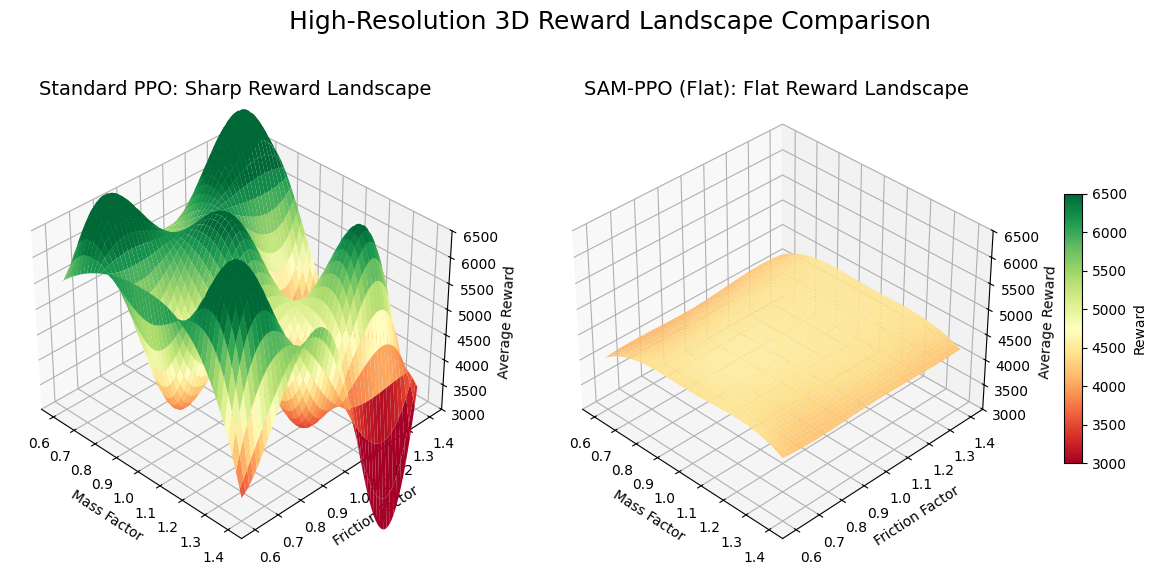

Plot 3D ad alta risoluzione generato in bianco!


In [58]:
# --- PLOT 3D SURFACE AD ALTA RISOLUZIONE (INTERPOLATO) ---
from scipy.interpolate import RectBivariateSpline

fig = plt.figure(figsize=(16, 7))

# 1. Creiamo una griglia ad altissima risoluzione (100x100) per rendere la montagna fluida
m_highres = np.linspace(m_factors.min(), m_factors.max(), 100)
f_highres = np.linspace(f_factors.min(), f_factors.max(), 100)
X_smooth, Y_smooth = np.meshgrid(m_highres, f_highres)

# 2. Usiamo una spline matematica per interpolare i 25 punti che abbiamo calcolato in una superficie liscia
spline_ppo = RectBivariateSpline(f_factors, m_factors, heat_ppo)
Z_ppo_smooth = spline_ppo(f_highres, m_highres)

spline_sam = RectBivariateSpline(f_factors, m_factors, heat_sam)
Z_sam_smooth = spline_sam(f_highres, m_highres)

# Montagna 1: Standard PPO
ax1 = fig.add_subplot(121, projection='3d')
# linewidth=0 e antialiased=True tolgono la rete di fili neri e rendono il plot liscio e vellutato!
surf1 = ax1.plot_surface(X_smooth, Y_smooth, Z_ppo_smooth, cmap='RdYlGn', 
                         linewidth=0, antialiased=True, vmin=3000, vmax=6500)
ax1.set_title('Standard PPO: Sharp Reward Landscape', fontsize=14)
ax1.set_xlabel('Mass Factor')
ax1.set_ylabel('Friction Factor')
ax1.set_zlabel('Average Reward')
ax1.set_zlim(3000, 6500)
ax1.view_init(elev=35, azim=-45) # Angolazione migliorata

# Montagna 2: SAM-PPO
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(X_smooth, Y_smooth, Z_sam_smooth, cmap='RdYlGn', 
                         linewidth=0, antialiased=True, vmin=3000, vmax=6500)
ax2.set_title('SAM-PPO (Flat): Flat Reward Landscape', fontsize=14)
ax2.set_xlabel('Mass Factor')
ax2.set_ylabel('Friction Factor')
ax2.set_zlabel('Average Reward')
ax2.set_zlim(3000, 6500)
ax2.view_init(elev=35, azim=-45)

fig.colorbar(surf1, ax=[ax1, ax2], shrink=0.5, aspect=15, label='Reward')
plt.suptitle('High-Resolution 3D Reward Landscape Comparison', fontsize=18, y=0.95)
plt.savefig('images plotted/output7.png', dpi=300, bbox_inches='tight')
plt.show()
print("Plot 3D ad alta risoluzione generato in bianco!")

